# Maritime Survival Rates

How does recorded survival proportion differ by passenger class and crew?

Data: [datasets/Titanic](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/Titanic.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Aggregated historical counts; passenger composition and access differ across groups.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Maritime Survival Rates',
 'executed_utc': '2026-11-21T10:14:13.908996+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/datasets/Titanic.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/datasets/Titanic.html',
 'sha256': 'ca983380c99d10ece64011fef5e07150ce49949d52b517e3fc55c7715938d179',
 'raw_rows': 32,
 'analysis_rows': 32,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,32
1,Class,object,0,0.0,4
2,Sex,object,0,0.0,2
3,Age,object,0,0.0,2
4,Survived,object,0,0.0,2
5,Freq,int64,0,0.0,22


## SQL and analysis
Frequency-weighted survival percentage = 100 × surviving people / all recorded people, grouped by class.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "Class" AS segment, COUNT(*) AS rows_used, 100.0 * SUM(CASE WHEN "Survived" = 'Yes' THEN "Freq" ELSE 0 END) / NULLIF(SUM("Freq"),0) AS metric, MIN("Freq") AS minimum, MAX("Freq") AS maximum FROM observations GROUP BY "Class" ORDER BY "Class";

The largest observed survival percentage is 62.462 for 1st. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,1st,8,62.461538,0,140
1,2nd,8,41.403509,0,154
2,3rd,8,25.212465,13,387
3,Crew,8,23.954802,0,670


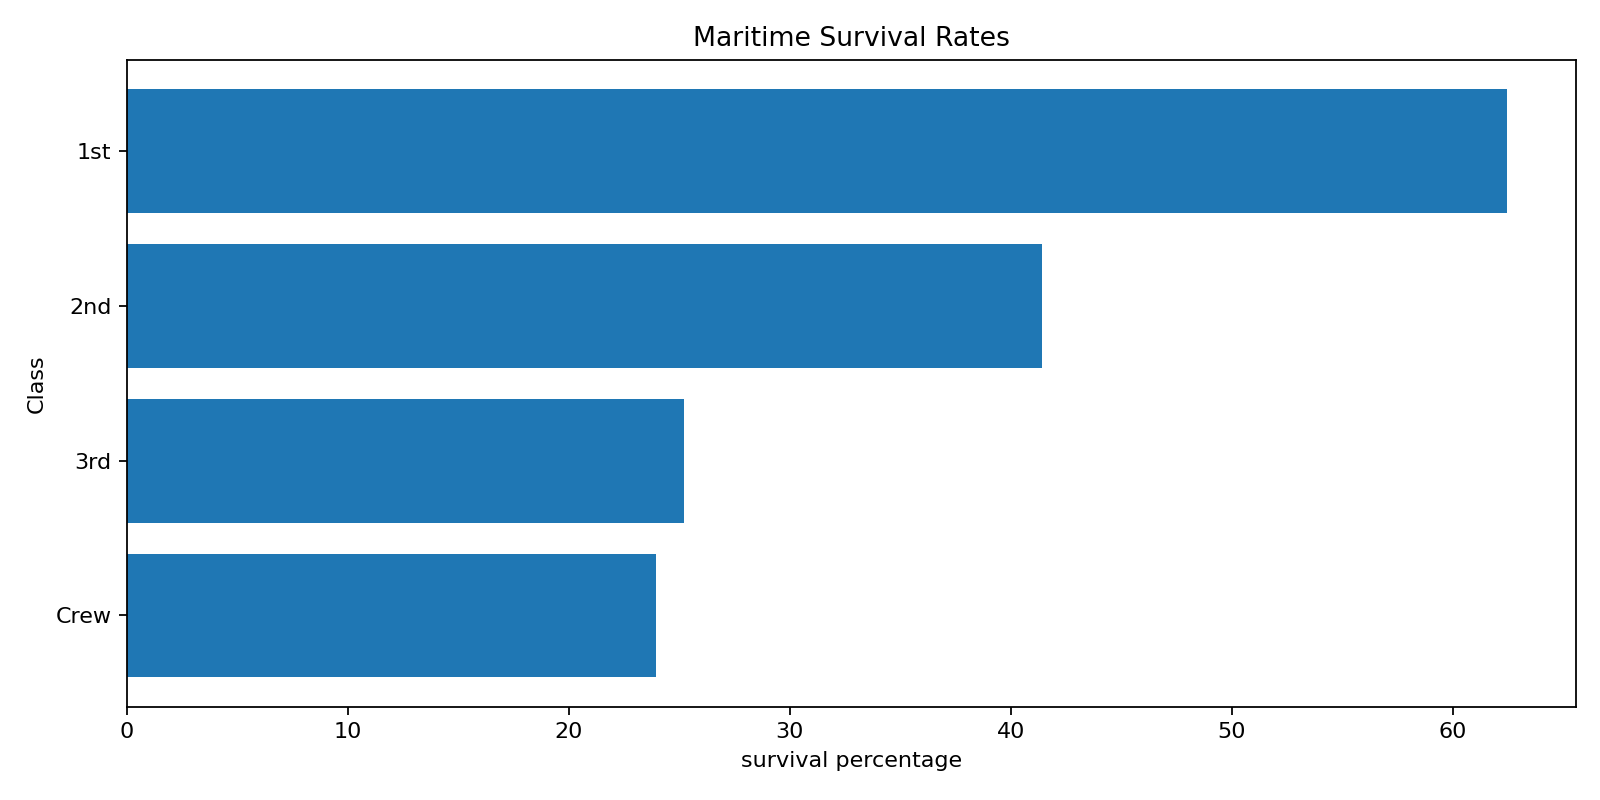

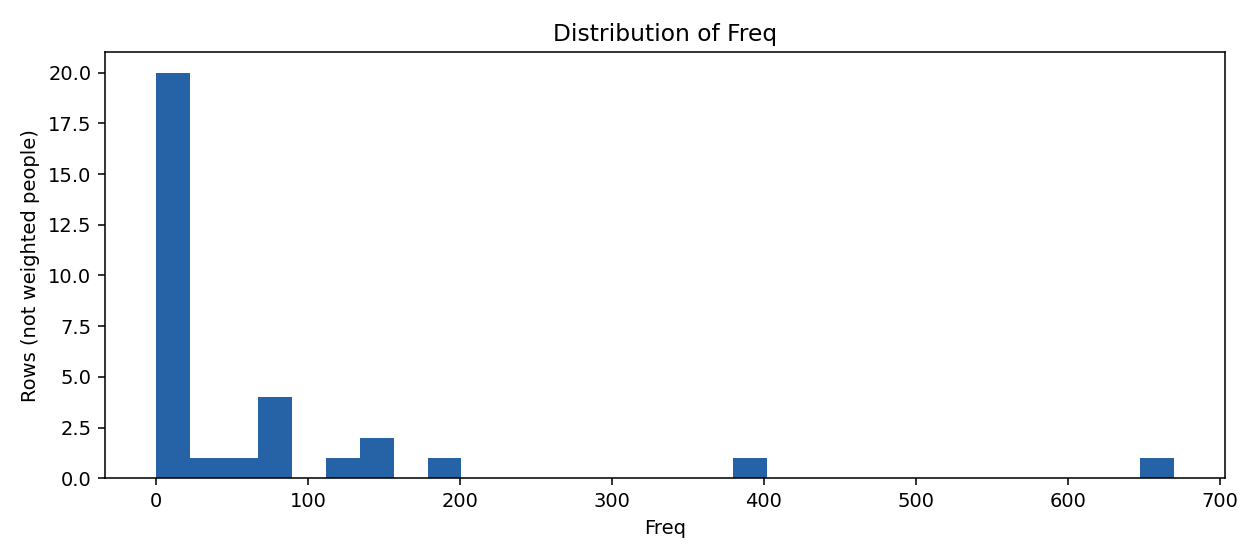

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Aggregated historical counts; passenger composition and access differ across groups.

**Next action:** Compare age- and sex-stratified survival rates before attributing causes.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.